# EDA — Kaggle Pixel Understanding
**Student:** [Tên / MSSV]  
**Goal:** Phân tích dữ liệu text và thiết kế pipeline chuyển đổi sang non-text representation (pixel image) để đưa vào model.

Các câu hỏi EDA cần trả lời:
1. Cấu trúc và thống kê cơ bản của dataset
2. Phân tích độ dài context và target
3. Phân tích theo ngôn ngữ
4. Kiểm tra split strategy (context/target có hợp lý không?)
5. Kiểm tra leakage
6. Thiết kế và validate pipeline render text → image
7. Phân tích ảnh hưởng của render params lên OCR quality

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image, ImageDraw, ImageFont
from collections import Counter
import os, re, textwrap

# ── Paths ──────────────────────────────────────────────────────────────────
TRAIN_FILE = 'train-3.csv'
TEST_FILE  = 'test.csv'

# ── Render params (must match train/inference) ─────────────────────────────
FONT_SIZE = 18
PADDING   = 12

print('Setup done.')

Setup done.


## 1. Load & Inspect Raw Data

In [2]:
train = pd.read_csv(TRAIN_FILE)
test  = pd.read_csv(TEST_FILE)

print('=== TRAIN ===')
print(f'Shape: {train.shape}')
print(f'Columns: {list(train.columns)}')
print()
train.head(3)

=== TRAIN ===
Shape: (1450, 5)
Columns: ['id', 'language', 'context', 'target', 'max_width']



,id,language,context,target,max_width
0,0,French,"Le 01.05.2014, le tourisme et le secteur du vo...","touristes viennent en grand nombre, et les tra...",812
1,1,English,"On 01.05.2014, tourism and the travel sector s...","come in large numbers, and fast trains make tr...",561
2,2,French,"Pour l'avenir, on voit une tendance vers le to...",aiment aussi les expériences locales: cuisiner...,887


In [3]:
print('=== TEST ===')
print(f'Shape: {test.shape}')
print(f'Columns: {list(test.columns)}')
print()
test.head(3)

=== TEST ===
Shape: (364, 4)
Columns: ['id', 'language', 'context', 'max_width']



,id,language,context,max_width
0,1450,French,Beaucoup de voyageurs préfèrent les séjours co...,648
1,1451,English,"Many travelers prefer short stays, three to fi...",615
2,1452,French,"Le 7 octobre 2017, le secteur des semi-conduct...",674


In [4]:
# Check for missing values
print('Missing values (train):')
print(train.isnull().sum())
print()
print('Missing values (test):')
print(test.isnull().sum())

Missing values (train):
id           0
language     0
context      0
target       0
max_width    0
dtype: int64

Missing values (test):
id           0
language     0
context      0
max_width    0
dtype: int64


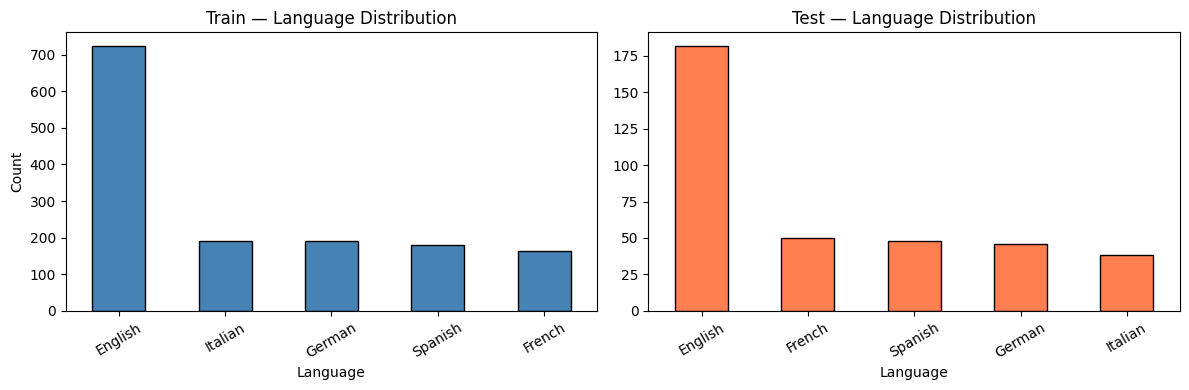

Train lang counts:
language
English    725
Italian    191
German     191
Spanish    180
French     163
Name: count, dtype: int64

Test lang counts:
language
English    182
French      50
Spanish     48
German      46
Italian     38
Name: count, dtype: int64


In [5]:
# Language distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train['language'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Train — Language Distribution')
axes[0].set_xlabel('Language')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

test['language'].value_counts().plot(kind='bar', ax=axes[1], color='coral', edgecolor='black')
axes[1].set_title('Test — Language Distribution')
axes[1].set_xlabel('Language')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('eda_language_dist.png', dpi=120, bbox_inches='tight')
plt.show()

print('Train lang counts:')
print(train['language'].value_counts())
print()
print('Test lang counts:')
print(test['language'].value_counts())

## 2. Text Length Analysis

In [6]:
# Character-level lengths
train['ctx_len']  = train['context'].str.len()
train['tgt_len']  = train['target'].str.len()
train['total_len'] = train['ctx_len'] + train['tgt_len']
train['tgt_ratio'] = train['tgt_len'] / train['total_len']  # should be ~0.20

# Word-level lengths
train['ctx_words'] = train['context'].str.split().str.len()
train['tgt_words'] = train['target'].str.split().str.len()

print('=== TARGET LENGTH STATISTICS (chars) ===')
print(train['tgt_len'].describe().round(1))
print()
print('=== CONTEXT LENGTH STATISTICS (chars) ===')
print(train['ctx_len'].describe().round(1))
print()
print('=== TARGET/TOTAL RATIO (should be ~0.20) ===')
print(train['tgt_ratio'].describe().round(3))

=== TARGET LENGTH STATISTICS (chars) ===
count    1450.0
mean       57.1
std        19.8
min        16.0
25%        43.0
50%        54.0
75%        68.0
max       156.0
Name: tgt_len, dtype: float64

=== CONTEXT LENGTH STATISTICS (chars) ===
count    1450.0
mean      211.0
std        71.7
min        66.0
25%       161.0
50%       198.0
75%       250.0
max       554.0
Name: ctx_len, dtype: float64

=== TARGET/TOTAL RATIO (should be ~0.20) ===
count    1450.000
mean        0.214
std         0.028
min         0.130
25%         0.195
50%         0.213
75%         0.231
max         0.333
Name: tgt_ratio, dtype: float64


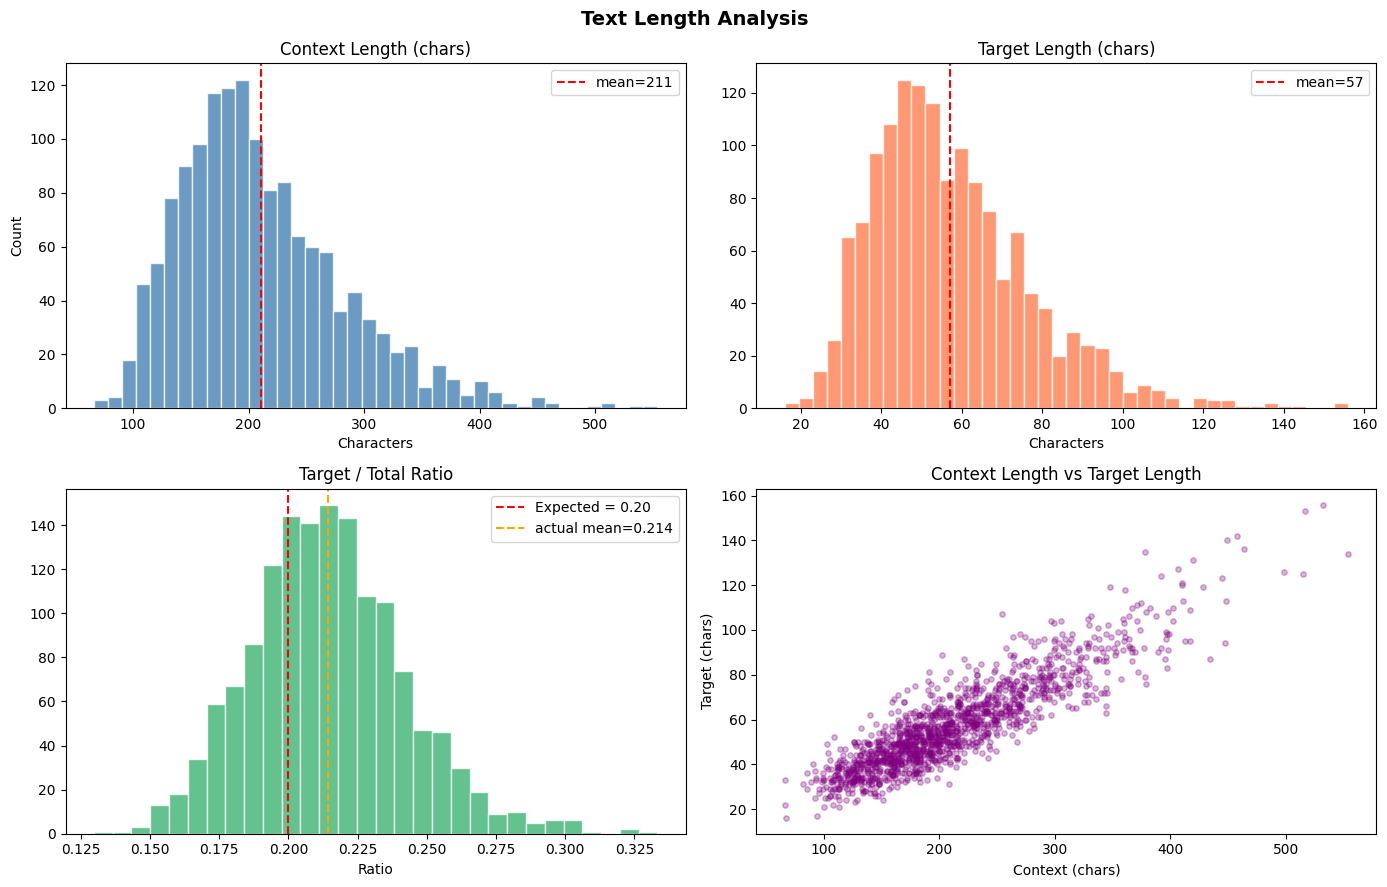

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Context length distribution
axes[0,0].hist(train['ctx_len'], bins=40, color='steelblue', edgecolor='white', alpha=0.8)
axes[0,0].axvline(train['ctx_len'].mean(), color='red', linestyle='--', label=f"mean={train['ctx_len'].mean():.0f}")
axes[0,0].set_title('Context Length (chars)')
axes[0,0].set_xlabel('Characters')
axes[0,0].set_ylabel('Count')
axes[0,0].legend()

# Target length distribution
axes[0,1].hist(train['tgt_len'], bins=40, color='coral', edgecolor='white', alpha=0.8)
axes[0,1].axvline(train['tgt_len'].mean(), color='red', linestyle='--', label=f"mean={train['tgt_len'].mean():.0f}")
axes[0,1].set_title('Target Length (chars)')
axes[0,1].set_xlabel('Characters')
axes[0,1].legend()

# Target/Total ratio
axes[1,0].hist(train['tgt_ratio'], bins=30, color='mediumseagreen', edgecolor='white', alpha=0.8)
axes[1,0].axvline(0.20, color='red', linestyle='--', label='Expected = 0.20')
axes[1,0].axvline(train['tgt_ratio'].mean(), color='orange', linestyle='--', label=f"actual mean={train['tgt_ratio'].mean():.3f}")
axes[1,0].set_title('Target / Total Ratio')
axes[1,0].set_xlabel('Ratio')
axes[1,0].legend()

# Context vs Target scatter
axes[1,1].scatter(train['ctx_len'], train['tgt_len'], alpha=0.3, s=15, color='purple')
axes[1,1].set_title('Context Length vs Target Length')
axes[1,1].set_xlabel('Context (chars)')
axes[1,1].set_ylabel('Target (chars)')

plt.suptitle('Text Length Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_lengths.png', dpi=120, bbox_inches='tight')
plt.show()

=== TARGET LENGTH PER LANGUAGE ===
          mean_chars  std_chars  min_chars  max_chars  count
language                                                    
English         54.3       18.6         16        142    725
French          61.4       18.2         27        135    163
German          71.0       24.4         17        156    191
Italian         56.1       18.8         24        136    191
Spanish         51.0       13.4         24         99    180


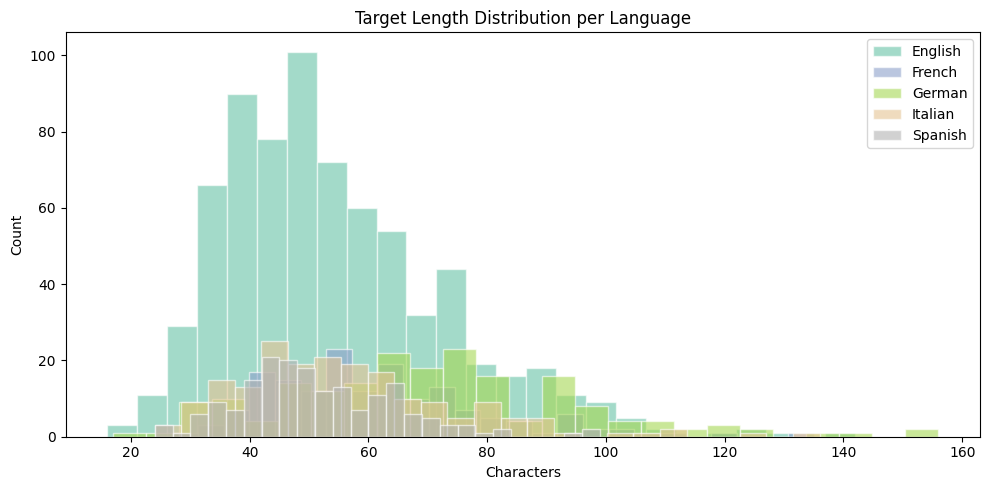

In [8]:
# Per-language length stats
print('=== TARGET LENGTH PER LANGUAGE ===')
lang_stats = train.groupby('language')['tgt_len'].agg(['mean','std','min','max','count'])
lang_stats.columns = ['mean_chars', 'std_chars', 'min_chars', 'max_chars', 'count']
print(lang_stats.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
langs = train['language'].unique()
colors = plt.cm.Set2(np.linspace(0, 1, len(langs)))
for i, lang in enumerate(sorted(langs)):
    subset = train[train['language'] == lang]['tgt_len']
    ax.hist(subset, bins=25, alpha=0.6, label=lang, color=colors[i], edgecolor='white')

ax.set_title('Target Length Distribution per Language')
ax.set_xlabel('Characters')
ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.savefig('eda_length_per_lang.png', dpi=120, bbox_inches='tight')
plt.show()

## 3. Split Strategy Analysis
Đề nói context = first 80%, target = remaining 20%. Kiểm tra xem split có xảy ra ở word boundary không.

In [9]:
def check_split_boundary(row):
    """Check if context ends at a clean word/sentence boundary."""
    ctx = str(row['context'])
    tgt = str(row['target'])
    
    # Does context end with space or punctuation? (clean boundary)
    ends_clean = ctx[-1] in ' .,;:!?'
    
    # Does target start with space or capital? (continuation after boundary)
    starts_clean = tgt[0] in ' ' or (len(tgt) > 0 and tgt[0].isupper())
    
    # Does context end mid-word? (split inside a token)
    ends_midword = ctx[-1].isalpha() and len(tgt) > 0 and tgt[0].isalpha()
    
    return pd.Series({
        'ends_clean': ends_clean,
        'starts_clean': starts_clean,
        'ends_midword': ends_midword,
        'ctx_last5': ctx[-5:],
        'tgt_first5': tgt[:5],
    })

boundary = train.apply(check_split_boundary, axis=1)
train = pd.concat([train, boundary], axis=1)

print('Context ends at clean boundary (space/punct):', boundary['ends_clean'].sum(), 
      f'({boundary["ends_clean"].mean()*100:.1f}%)')
print('Target starts clean (space/capital):', boundary['starts_clean'].sum(),
      f'({boundary["starts_clean"].mean()*100:.1f}%)')
print('Split mid-word:', boundary['ends_midword'].sum(),
      f'({boundary["ends_midword"].mean()*100:.1f}%)')

print('\nSample boundaries (ctx_last5 | tgt_first5):')
sample = train[['ctx_last5', 'tgt_first5', 'language']].sample(10, random_state=42)
for _, row in sample.iterrows():
    print(f"  [{row['language']:>8s}]  ...{repr(row['ctx_last5'])}  |  {repr(row['tgt_first5'])}...")

Context ends at clean boundary (space/punct): 191 (13.2%)
Target starts clean (space/capital): 140 (9.7%)
Split mid-word: 1250 (86.2%)

Sample boundaries (ctx_last5 | tgt_first5):
  [  German]  ...'Fotos'  |  'sende'...
  [  German]  ...'geben'  |  'etwas'...
  [ English]  ...'felt.'  |  'Marke'...
  [  French]  ...'auver'  |  'des v'...
  [ English]  ...' when'  |  'the I'...
  [  German]  ...'urer.'  |  'Auch '...
  [ Italian]  ...'orma,'  |  'chi s'...
  [ English]  ...'ities'  |  'also '...
  [ Italian]  ...'ia di'  |  'una c'...
  [ English]  ...'there'  |  'are n'...


## 4. Leakage Check
Kiểm tra xem target có bị lộ trong context không.

In [10]:
def check_leakage(row):
    ctx = str(row['context']).lower()
    tgt = str(row['target']).lower().strip()
    # Does the first 20 chars of target appear somewhere in context?
    probe = tgt[:20]
    return probe in ctx

leakage = train.apply(check_leakage, axis=1)
print(f'Samples where target prefix appears in context: {leakage.sum()} / {len(train)}')
if leakage.sum() > 0:
    print('  ⚠ Possible leakage — inspect these rows:')
    print(train[leakage][['context','target','language']].head(3))
else:
    print('  ✓ No leakage detected.')

Samples where target prefix appears in context: 0 / 1450
  ✓ No leakage detected.


## 5. Non-Text Representation Design
Pipeline: `context text → render PIL image (white text, black bg) → pixel_values tensor`

Đây là bước cốt lõi của competition — model nhận pixel_values, không nhận raw text.

Font loaded: C:/Windows/Fonts/times.ttf

Sample: [French]
Context (first 80 chars): Le 01.05.2014, le tourisme et le secteur du voyage montrent des tendances claire...
Rendered to: 812×90 px  (3 lines)


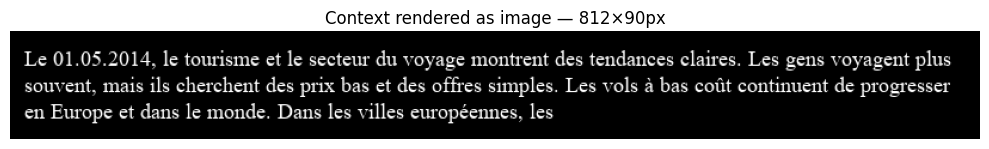

In [11]:
def get_font(font_size):
    font_paths = [
        'C:/Windows/Fonts/times.ttf',
        'C:/Windows/Fonts/arial.ttf',
        '/usr/share/fonts/truetype/liberation/LiberationSerif-Regular.ttf',
        '/usr/share/fonts/truetype/dejavu/DejaVuSerif.ttf',
    ]
    for path in font_paths:
        if os.path.exists(path):
            return ImageFont.truetype(path, font_size), path
    return ImageFont.load_default(), 'default'

def render_text(text, max_width, font_size=18, padding=12):
    font, _ = get_font(font_size)
    words = text.split()
    lines, current = [], ''
    content_width = max_width - 2 * padding
    for word in words:
        test = f'{current} {word}'.strip()
        bbox = font.getbbox(test)
        if bbox[2] - bbox[0] <= content_width:
            current = test
        else:
            if current:
                lines.append(current)
            current = word
    if current:
        lines.append(current)
    if not lines:
        lines = ['.']
    
    line_h = font_size + 4
    img = Image.new('L', (max_width, len(lines) * line_h + 2 * padding), 0)
    draw = ImageDraw.Draw(img)
    y = padding
    for line in lines:
        draw.text((padding, y), line, fill=255, font=font)
        y += line_h
    return img, lines

font, font_path = get_font(FONT_SIZE)
print(f'Font loaded: {font_path}')

# Show a sample render
sample_row = train.iloc[0]
img, lines = render_text(sample_row['context'], int(sample_row['max_width']))
print(f'\nSample: [{sample_row["language"]}]')
print(f'Context (first 80 chars): {sample_row["context"][:80]}...')
print(f'Rendered to: {img.size[0]}×{img.size[1]} px  ({len(lines)} lines)')

plt.figure(figsize=(10, 3))
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title(f'Context rendered as image — {img.size[0]}×{img.size[1]}px')
plt.axis('off')
plt.tight_layout()
plt.savefig('eda_render_sample.png', dpi=120, bbox_inches='tight')
plt.show()

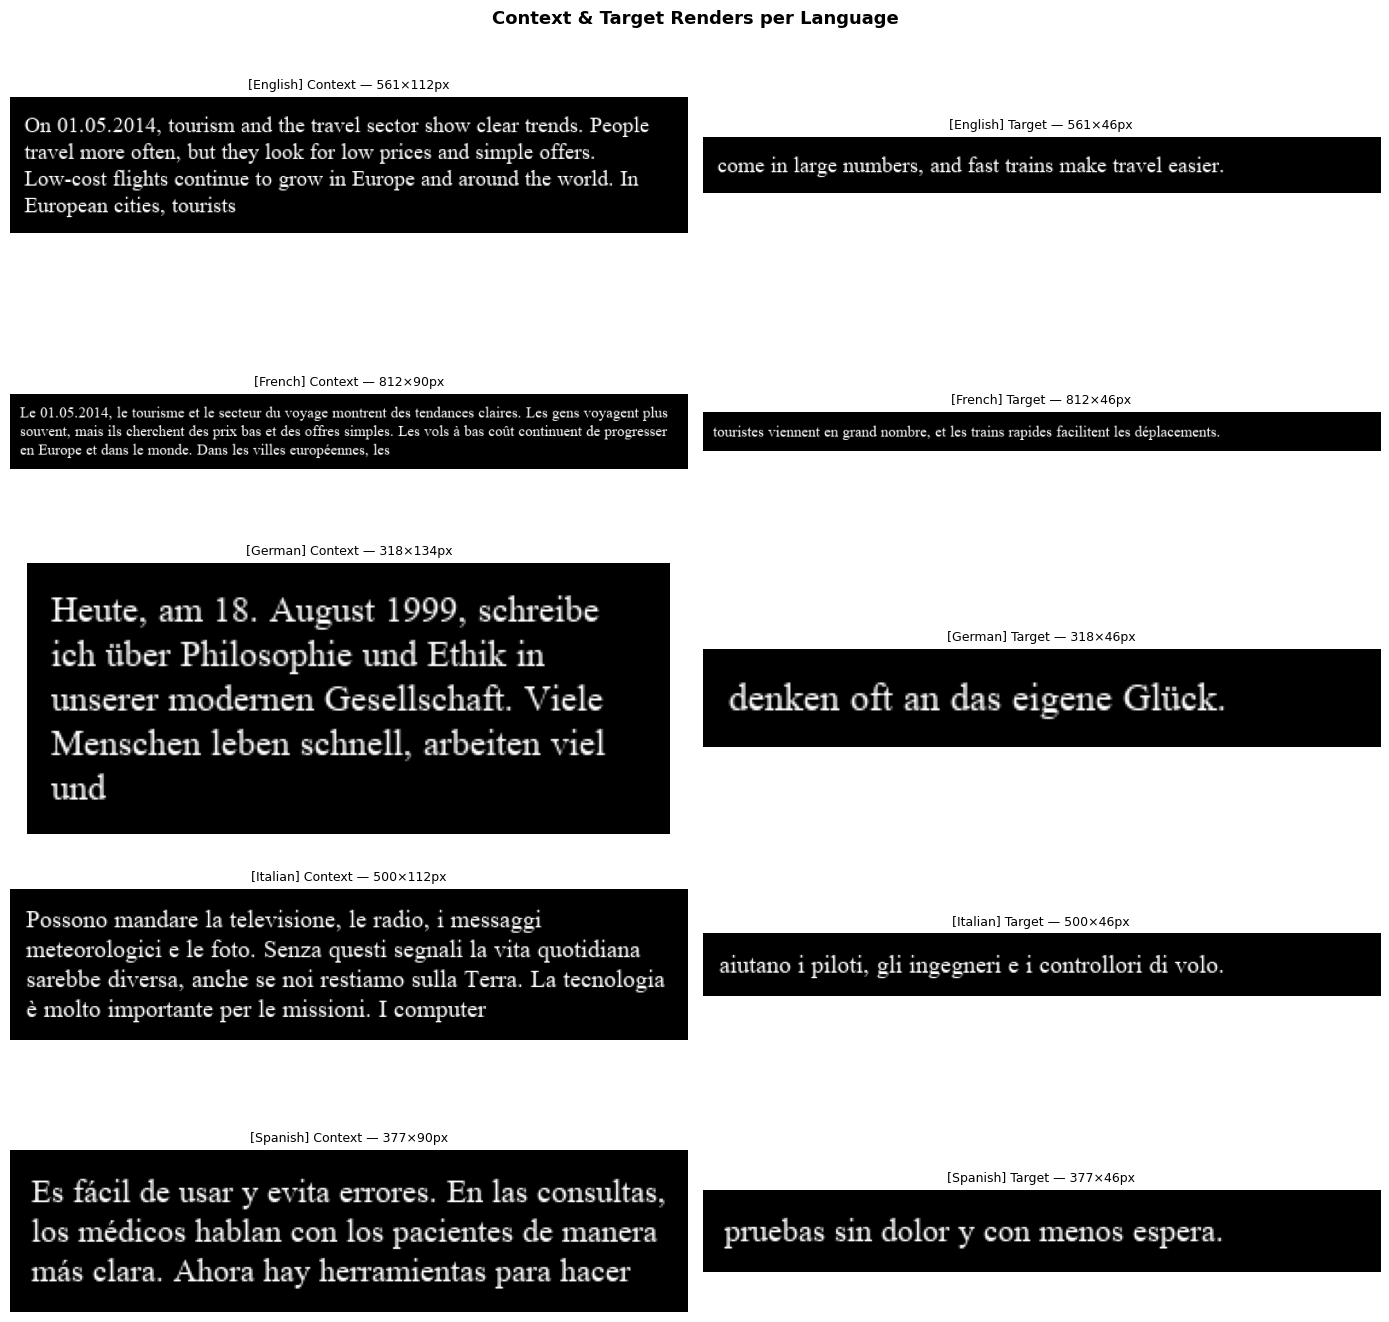

In [12]:
# Show renders for all 5 languages side by side
fig, axes = plt.subplots(5, 2, figsize=(14, 14))
langs = sorted(train['language'].unique())

for i, lang in enumerate(langs):
    row = train[train['language'] == lang].iloc[0]
    w = int(row['max_width'])
    
    ctx_img, _ = render_text(str(row['context']), w, FONT_SIZE, PADDING)
    tgt_img, _ = render_text(str(row['target']),  w, FONT_SIZE, PADDING)
    
    axes[i, 0].imshow(ctx_img, cmap='gray', vmin=0, vmax=255)
    axes[i, 0].set_title(f'[{lang}] Context — {ctx_img.size[0]}×{ctx_img.size[1]}px', fontsize=9)
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(tgt_img, cmap='gray', vmin=0, vmax=255)
    axes[i, 1].set_title(f'[{lang}] Target — {tgt_img.size[0]}×{tgt_img.size[1]}px', fontsize=9)
    axes[i, 1].axis('off')

plt.suptitle('Context & Target Renders per Language', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_renders_all_langs.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. Render Parameter Analysis
Phân tích ảnh hưởng của `max_width`, `font_size`, `padding` lên image dimensions và pixel density.

=== max_width STATISTICS ===
count    1450.0
mean      559.2
std       195.5
min       155.0
25%       420.0
50%       523.0
75%       663.0
max      1586.0
Name: max_width, dtype: float64

Unique max_width values: [np.int64(155), np.int64(179), np.int64(207), np.int64(216), np.int64(220), np.int64(224), np.int64(229), np.int64(241), np.int64(247), np.int64(248), np.int64(252), np.int64(253), np.int64(254), np.int64(255), np.int64(261), np.int64(262), np.int64(263), np.int64(265), np.int64(268), np.int64(269), np.int64(270), np.int64(271), np.int64(273), np.int64(274), np.int64(275), np.int64(279), np.int64(281), np.int64(282), np.int64(284), np.int64(285), np.int64(286), np.int64(287), np.int64(289), np.int64(292), np.int64(293), np.int64(295), np.int64(296), np.int64(297), np.int64(299), np.int64(300), np.int64(301), np.int64(303), np.int64(305), np.int64(306), np.int64(307), np.int64(308), np.int64(309), np.int64(310), np.int64(311), np.int64(312), np.int64(313), np.int64(314), np.i

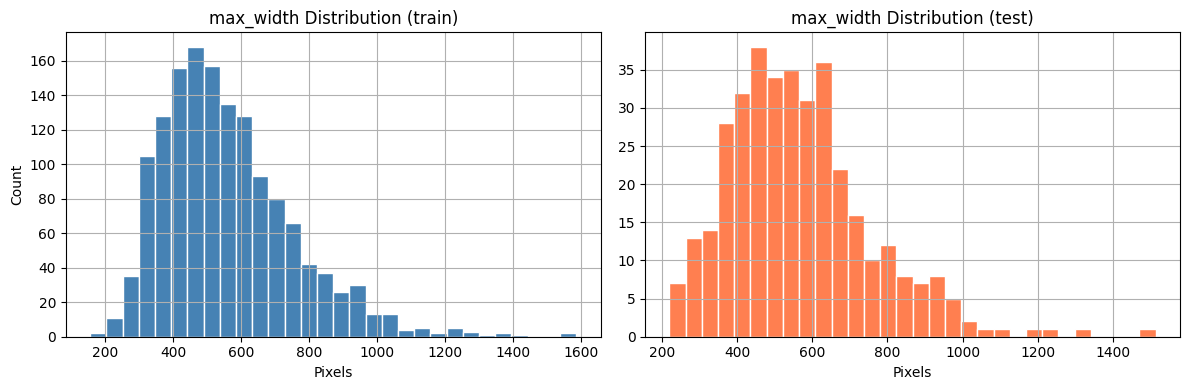

In [13]:
# max_width distribution
print('=== max_width STATISTICS ===')
print(train['max_width'].describe().round(1))
print(f'\nUnique max_width values: {sorted(train["max_width"].unique())}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train['max_width'].hist(bins=30, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('max_width Distribution (train)')
axes[0].set_xlabel('Pixels')
axes[0].set_ylabel('Count')

if 'max_width' in test.columns:
    test['max_width'].hist(bins=30, ax=axes[1], color='coral', edgecolor='white')
    axes[1].set_title('max_width Distribution (test)')
    axes[1].set_xlabel('Pixels')

plt.tight_layout()
plt.savefig('eda_maxwidth.png', dpi=120, bbox_inches='tight')
plt.show()

Computing rendered image sizes for all train samples...
=== RENDERED TARGET IMAGE SIZE ===
Height: min=46  max=46  mean=46
Width:  min=155   max=1586   mean=559
Lines:  min=1 max=1 mean=1.0


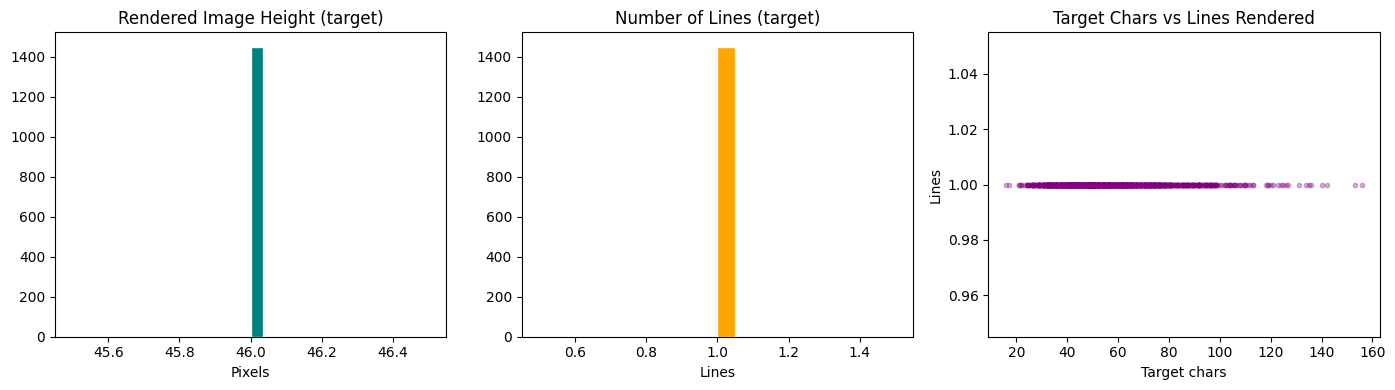

In [14]:
# Compute rendered image dimensions for all train samples
print('Computing rendered image sizes for all train samples...')
img_heights, img_widths, n_lines_list = [], [], []

for _, row in train.iterrows():
    img, lines = render_text(str(row['target']), int(row['max_width']), FONT_SIZE, PADDING)
    img_heights.append(img.size[1])
    img_widths.append(img.size[0])
    n_lines_list.append(len(lines))

train['img_height'] = img_heights
train['img_width']  = img_widths
train['n_lines']    = n_lines_list

print('=== RENDERED TARGET IMAGE SIZE ===')
print(f'Height: min={min(img_heights)}  max={max(img_heights)}  mean={np.mean(img_heights):.0f}')
print(f'Width:  min={min(img_widths)}   max={max(img_widths)}   mean={np.mean(img_widths):.0f}')
print(f'Lines:  min={min(n_lines_list)} max={max(n_lines_list)} mean={np.mean(n_lines_list):.1f}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(img_heights, bins=30, color='teal', edgecolor='white')
axes[0].set_title('Rendered Image Height (target)')
axes[0].set_xlabel('Pixels')

axes[1].hist(n_lines_list, bins=20, color='orange', edgecolor='white')
axes[1].set_title('Number of Lines (target)')
axes[1].set_xlabel('Lines')

axes[2].scatter(train['tgt_len'], train['n_lines'], alpha=0.3, s=10, color='purple')
axes[2].set_title('Target Chars vs Lines Rendered')
axes[2].set_xlabel('Target chars')
axes[2].set_ylabel('Lines')

plt.tight_layout()
plt.savefig('eda_render_dims.png', dpi=120, bbox_inches='tight')
plt.show()

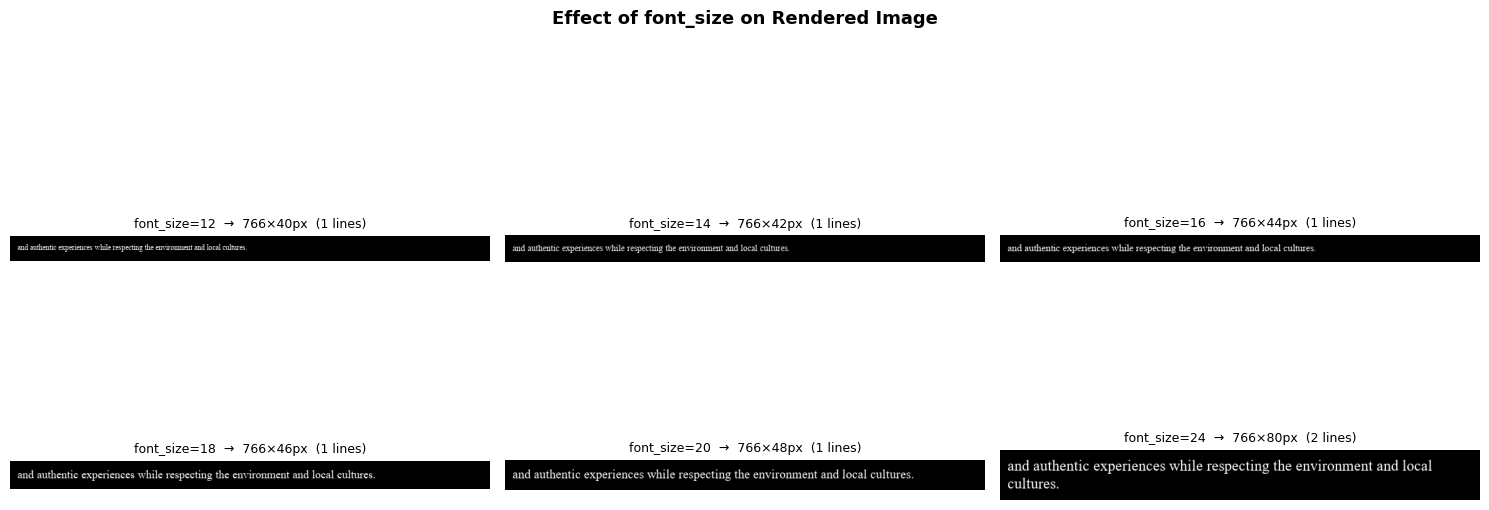

Sample text: "and authentic experiences while respecting the environment a..."
max_width: 766
Current config uses font_size=18 — ↑ larger = more pixels, potentially better OCR


In [16]:
# Font size experiment: how does font_size affect readability?
sample_text = train.iloc[5]['target']
sample_width = int(train.iloc[5]['max_width'])

font_sizes = [12, 14, 16, 18, 20, 24]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for ax, fs in zip(axes.flat, font_sizes):
    img, lines = render_text(sample_text, sample_width, fs, PADDING)
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'font_size={fs}  →  {img.size[0]}×{img.size[1]}px  ({len(lines)} lines)', fontsize=9)
    ax.axis('off')

plt.suptitle('Effect of font_size on Rendered Image', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_font_sizes.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Sample text: "{sample_text[:60]}..."')
print(f'max_width: {sample_width}')
print(
    f"Current config uses font_size={FONT_SIZE} — "
    f"{'↑ larger = more pixels, potentially better OCR' if FONT_SIZE >= 18 else '↓ smaller = denser layout'}"
)

## 7. Pixel Statistics
Phân tích mật độ pixel (số white pixels / tổng pixels) — ảnh hưởng trực tiếp đến evaluation metric.

=== PIXEL DENSITY (white / total) ===
  mean:  0.0519
  std:   0.0025
  min:   0.0458
  max:   0.0591

=== WHITE PIXEL COUNT PER SAMPLE ===
  mean:  1364
  std:   543
  min:   511
  max:   3456


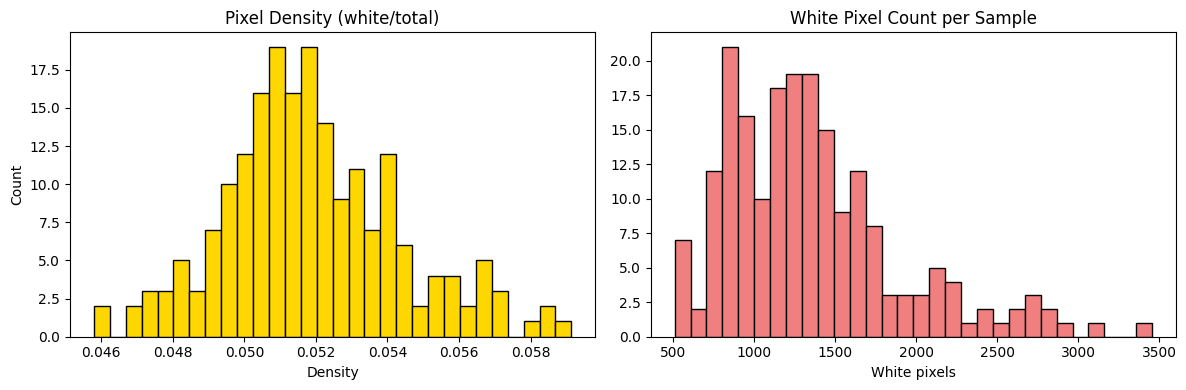

In [17]:
import numpy as np

def pixel_stats(img, threshold=127):
    arr = np.array(img)
    total = arr.size
    white = int((arr > threshold).sum())
    return white, total, white / total

# Compute pixel density for a sample of train
sample_train = train.sample(min(200, len(train)), random_state=42)
densities = []
white_counts = []

for _, row in sample_train.iterrows():
    img, _ = render_text(str(row['target']), int(row['max_width']), FONT_SIZE, PADDING)
    w, t, d = pixel_stats(img)
    densities.append(d)
    white_counts.append(w)

print('=== PIXEL DENSITY (white / total) ===')
print(f'  mean:  {np.mean(densities):.4f}')
print(f'  std:   {np.std(densities):.4f}')
print(f'  min:   {np.min(densities):.4f}')
print(f'  max:   {np.max(densities):.4f}')
print()
print('=== WHITE PIXEL COUNT PER SAMPLE ===')
print(f'  mean:  {np.mean(white_counts):.0f}')
print(f'  std:   {np.std(white_counts):.0f}')
print(f'  min:   {np.min(white_counts)}')
print(f'  max:   {np.max(white_counts)}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(densities, bins=30, color='gold', edgecolor='black')
axes[0].set_title('Pixel Density (white/total)')
axes[0].set_xlabel('Density')
axes[0].set_ylabel('Count')

axes[1].hist(white_counts, bins=30, color='lightcoral', edgecolor='black')
axes[1].set_title('White Pixel Count per Sample')
axes[1].set_xlabel('White pixels')

plt.tight_layout()
plt.savefig('eda_pixel_stats.png', dpi=120, bbox_inches='tight')
plt.show()

## 8. Pipeline Consistency Check
Xác minh render pipeline nhất quán: cùng text + cùng params → cùng pixels (deterministic).

In [19]:
# Determinism check: render same text twice, compare pixel arrays
test_text = train.iloc[0]['target']
test_width = int(train.iloc[0]['max_width'])

img1, _ = render_text(test_text, test_width, FONT_SIZE, PADDING)
img2, _ = render_text(test_text, test_width, FONT_SIZE, PADDING)

arr1 = np.array(img1)
arr2 = np.array(img2)
identical = np.array_equal(arr1, arr2)

print(f'Render is deterministic: {identical}')
if not identical:
    diff = np.abs(arr1.astype(int) - arr2.astype(int))
    print(f'  Max pixel diff: {diff.max()}  Non-zero diffs: {(diff > 0).sum()}')
    print('  ⚠ Non-deterministic render will cause inconsistency between train and inference!')
else:
    print('  ✓ Safe to use in training.')

Render is deterministic: True
  ✓ Safe to use in training.


In [20]:
# Train vs Test max_width range alignment
train_w = set(train['max_width'].unique())
test_w  = set(test['max_width'].unique()) if 'max_width' in test.columns else set()

only_in_test = test_w - train_w
only_in_train = train_w - test_w

print('max_width values only in TEST (unseen at train time):', sorted(only_in_test) or 'None')
print('max_width values only in TRAIN:                      ', sorted(only_in_train) or 'None')

if only_in_test:
    print('  ⚠ Model will encounter unseen max_width values at inference!')
else:
    print('  ✓ Test max_width values all seen during training.')

max_width values only in TEST (unseen at train time): [np.int64(230), np.int64(236), np.int64(260), np.int64(272), np.int64(283), np.int64(294), np.int64(376), np.int64(384), np.int64(456), np.int64(483), np.int64(571), np.int64(576), np.int64(586), np.int64(609), np.int64(623), np.int64(628), np.int64(642), np.int64(662), np.int64(687), np.int64(708), np.int64(748), np.int64(758), np.int64(769), np.int64(783), np.int64(793), np.int64(799), np.int64(817), np.int64(839), np.int64(841), np.int64(852), np.int64(867), np.int64(869), np.int64(870), np.int64(898), np.int64(906), np.int64(917), np.int64(923), np.int64(931), np.int64(932), np.int64(935), np.int64(955), np.int64(981), np.int64(995), np.int64(1006), np.int64(1029), np.int64(1079), np.int64(1091), np.int64(1190), np.int64(1241), np.int64(1331), np.int64(1514)]
max_width values only in TRAIN:                       [np.int64(155), np.int64(179), np.int64(207), np.int64(216), np.int64(224), np.int64(229), np.int64(241), np.int64(248

## 9. Summary & Design Decisions
Tổng hợp insights từ EDA và các quyết định thiết kế cho Model Development.

In [21]:
print('=' * 65)
print('EDA SUMMARY')
print('=' * 65)

print(f'''
1. DATASET
   Train: {len(train)} samples | Test: {len(test)} samples
   Languages: {sorted(train["language"].unique())}
   Class imbalance: English dominates (~{train["language"].value_counts().iloc[0]/len(train)*100:.0f}% of train)

2. TEXT LENGTHS
   Context: mean={train["ctx_len"].mean():.0f} chars  std={train["ctx_len"].std():.0f}
   Target:  mean={train["tgt_len"].mean():.0f} chars  std={train["tgt_len"].std():.0f}
   Target/Total ratio: mean={train["tgt_ratio"].mean():.3f}  (expected ~0.200)

3. SPLIT BOUNDARY
   Mid-word splits: {boundary["ends_midword"].mean()*100:.1f}% of samples
   → Model must handle incomplete words at context boundary.

4. LEAKAGE
   Target prefix in context: {leakage.sum()} / {len(train)} samples

5. NON-TEXT REPRESENTATION
   Pipeline: text → PIL image (white on black, font_size={FONT_SIZE}, padding={PADDING})
   Rendered image: width=max_width, height varies by content
   Pixel density (target): mean={np.mean(densities):.4f}

6. RENDER PARAMS
   font_size={FONT_SIZE}: balances readability vs image size
   padding={PADDING}: consistent margins
   Deterministic: {identical}

7. DESIGN DECISIONS FOR MODEL DEVELOPMENT
   • Input to model: TrOCR pixel_values from rendered context image
     → Satisfies "non-text representation" requirement
   • Output of model: predicted target text string
   • Post-processing: render pred text → image → pixel coordinates
   • Evaluation: OCR reads rendered pixels → char similarity vs ground truth
''')

print('=' * 65)

EDA SUMMARY

1. DATASET
   Train: 1450 samples | Test: 364 samples
   Languages: ['English', 'French', 'German', 'Italian', 'Spanish']
   Class imbalance: English dominates (~50% of train)

2. TEXT LENGTHS
   Context: mean=211 chars  std=72
   Target:  mean=57 chars  std=20
   Target/Total ratio: mean=0.214  (expected ~0.200)

3. SPLIT BOUNDARY
   Mid-word splits: 86.2% of samples
   → Model must handle incomplete words at context boundary.

4. LEAKAGE
   Target prefix in context: 0 / 1450 samples

5. NON-TEXT REPRESENTATION
   Pipeline: text → PIL image (white on black, font_size=18, padding=12)
   Rendered image: width=max_width, height varies by content
   Pixel density (target): mean=0.0519

6. RENDER PARAMS
   font_size=18: balances readability vs image size
   padding=12: consistent margins
   Deterministic: True

7. DESIGN DECISIONS FOR MODEL DEVELOPMENT
   • Input to model: TrOCR pixel_values from rendered context image
     → Satisfies "non-text representation" requirement
   